In [1]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_netflix.csv to cleaned_netflix.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cleaned_netflix.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Basic dataset information

print("DATASET INFORMATION")
print("-------------------")

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe(include='all'))

print("\nDuplicate records:", df.duplicated().sum())

print("\nUnknown values in each column:")
print((df == 'Unknown').sum())

DATASET INFORMATION
-------------------

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Statistical summary:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,8807,8807,8807,8797,8807.000000,8807,8804,8807,8807
unique,8807,2,8806,4529,7693,749,1714,NaN,18,220,514,8775
top,s1,Movie,Consequences,Unknown,Unknown,United States,2020-01-01,NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,2,2634,825,2818,110,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN



Duplicate records: 0

Unknown values in each column:
show_id            0
type               0
title              1
director        2634
cast             825
country          831
date_added         0
release_year       0
rating             4
duration           0
listed_in          0
description        0
dtype: int64


type
Movie      6131
TV Show    2676
Name: count, dtype: int64


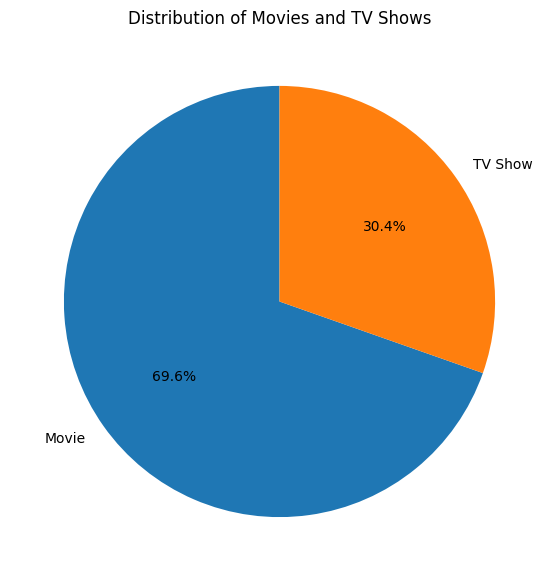

In [4]:
# Count Movies and TV Shows

content_counts = df['type'].value_counts()

print(content_counts)

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Movies and TV Shows')
plt.show()

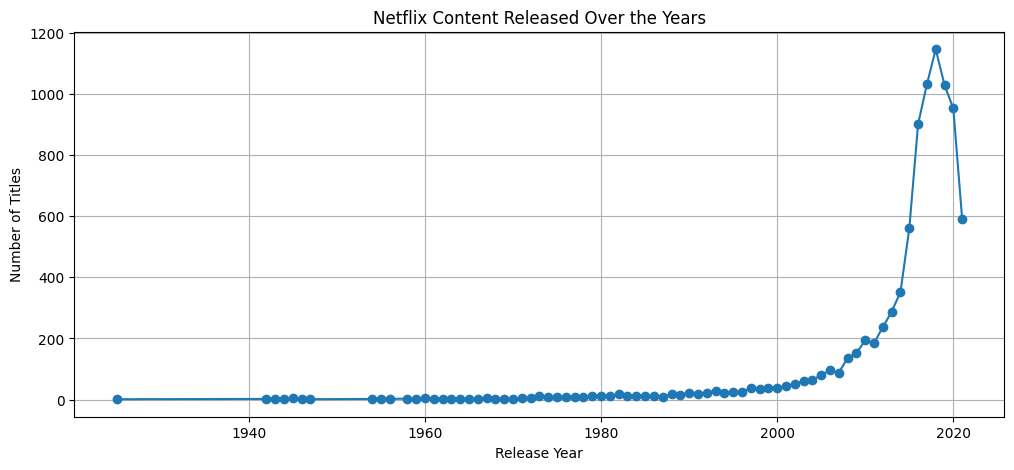

Year with highest content: 2018
Number of titles: 1147


In [5]:
# Count content released each year

year_counts = df['release_year'].value_counts().sort_index()

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(year_counts.index, year_counts.values, marker='o')

plt.title('Netflix Content Released Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

# Find the year with the highest number of releases
print("Year with highest content:", year_counts.idxmax())
print("Number of titles:", year_counts.max())

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


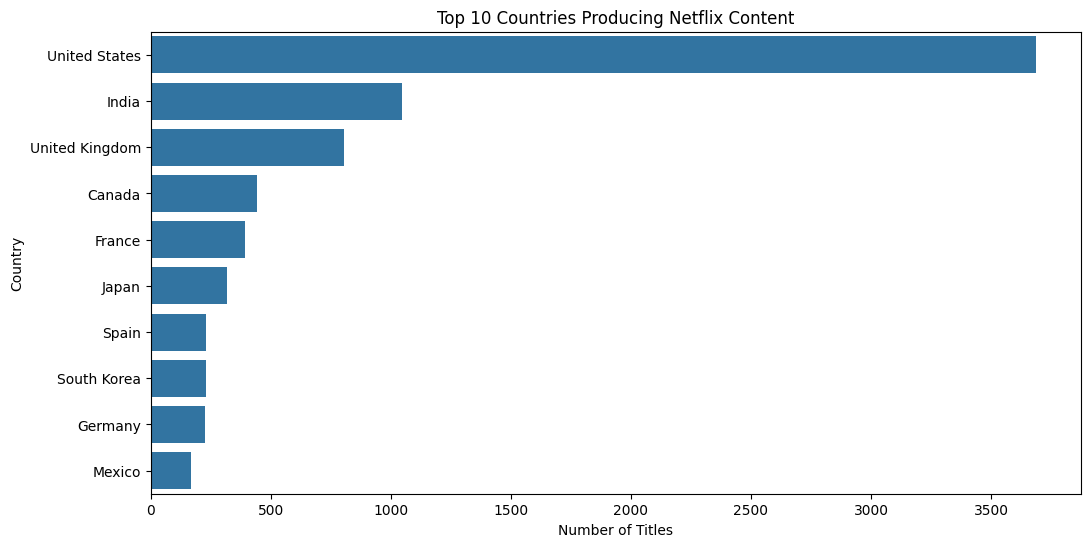

In [6]:
# Find the top 10 countries

country_counts = (
    df[df['country'] != 'Unknown']['country']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

print(country_counts)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


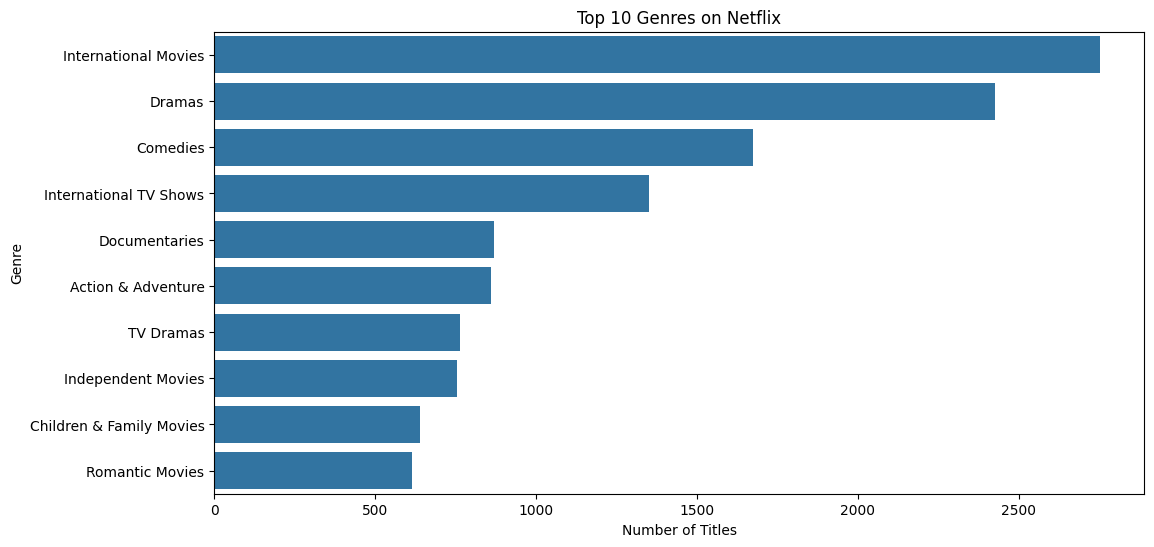

In [7]:
# Find the top 10 genres

genre_counts = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

print(genre_counts)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

Movie Duration Statistics
-------------------------
Average duration: 99.57718668407311
Median duration: 98.0
Shortest movie: 3.0
Longest movie: 312.0


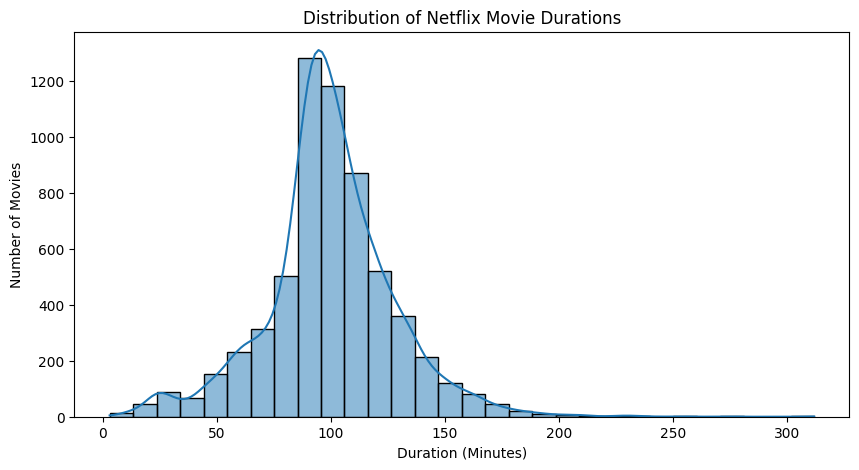

In [8]:
# Filter only Movies

movies = df[df['type'] == 'Movie'].copy()

# Extract duration in minutes

movies['duration_minutes'] = (
    movies['duration'].str.extract(r'(\d+)').astype(float)
)

# Calculate statistics

print("Movie Duration Statistics")
print("-------------------------")

print("Average duration:", movies['duration_minutes'].mean())
print("Median duration:", movies['duration_minutes'].median())
print("Shortest movie:", movies['duration_minutes'].min())
print("Longest movie:", movies['duration_minutes'].max())

# Create histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    movies['duration_minutes'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Netflix Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.show()

Top 10 Content Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


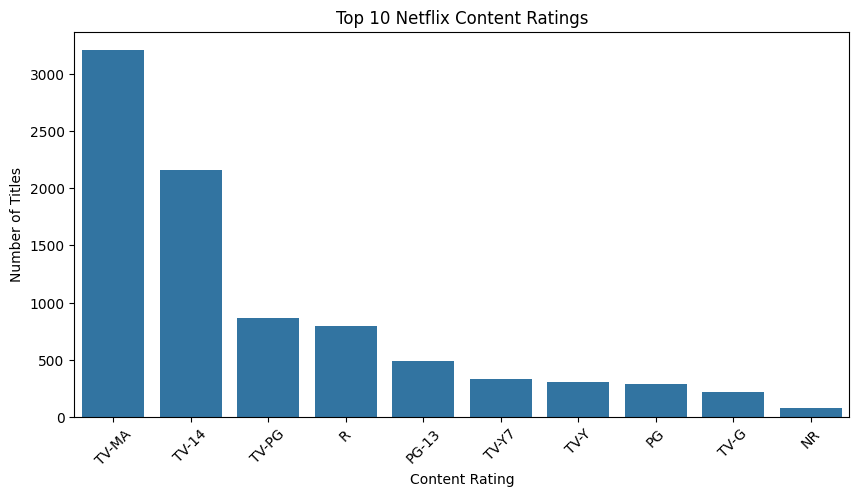

In [9]:
# Analyse content ratings

rating_counts = df['rating'].value_counts().head(10)

print("Top 10 Content Ratings:")
print(rating_counts)

# Create bar chart

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

Content Added Each Year:
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


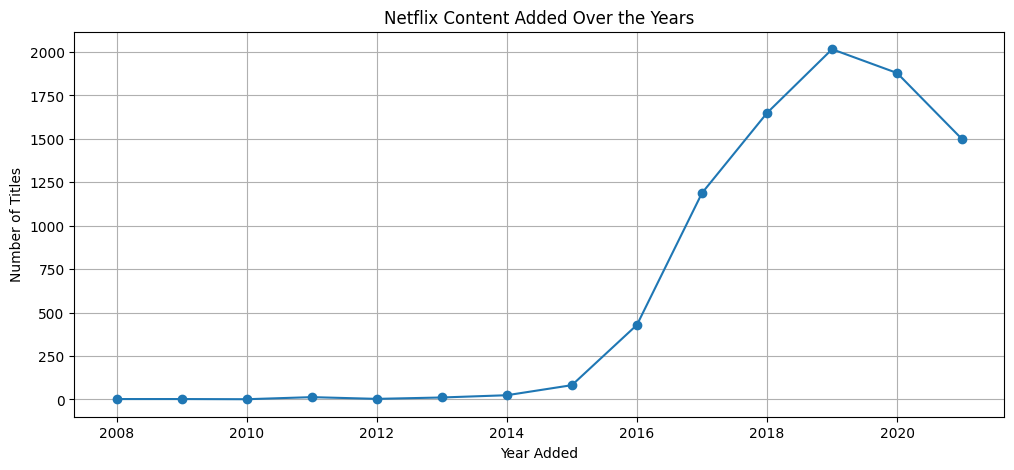


Year with most additions: 2019.0
Number of titles added: 2016


In [10]:
# Convert date_added into datetime format

df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

# Extract year from date_added

df['year_added'] = df['date_added'].dt.year

# Count titles added each year

added_counts = df['year_added'].value_counts().sort_index()

print("Content Added Each Year:")
print(added_counts)

# Create line chart

plt.figure(figsize=(12, 5))

plt.plot(
    added_counts.index,
    added_counts.values,
    marker='o'
)

plt.title('Netflix Content Added Over the Years')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

print("\nYear with most additions:", added_counts.idxmax())
print("Number of titles added:", added_counts.max())